# Steam Game Success Prediction: Feature Engineering, Model Training & Evaluation

## Overview
This notebook covers the complete machine learning pipeline for predicting the commercial success tier of Steam games (`Low`, `Medium`, `High`). 

### Key Pipeline Stages:
1. **Data Splitting:** Stratified train/validation/test partitioning (60% / 20% / 20%) to prevent data leakage and preserve target class proportions.
2. **Feature Encoding & NLP:** Multi-label binarization with dimensionality control (`top_k`), cross-validated target encoding for developers and publishers, and TF-IDF vectorization for game descriptions.
3. **Model Training & Hyperparameter Tuning:** Training and optimizing three distinct architectures—**Logistic Regression**, **Random Forest**, and **XGBoost**—using `RandomizedSearchCV` and Bayesian optimization (**Optuna**) with class imbalance handling.
4. **Model Evaluation & Comparison:** Assessing validation performance via Macro F1-score, Multiclass ROC AUC (OvR), and confusion matrices.
5. **Final Testing & Interpretability:** Evaluating the best-performing model on the unseen test set and analyzing key predictive drivers through feature importance.


## 1. Data Loading & Initial Setup

This section imports essential data manipulation and visualization libraries, loads the preprocessed Steam dataset and defines global constants (`RANDOM_STATE` and `N_JOBS`) to ensure full reproducibility across experiments.

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [18]:
df = pd.read_json("../data/processed/steam_games_processed.json")
df.head()

,appid,name,required_age,price,short_description,windows,mac,linux,achievements,supported_languages,...,genres,tags,release_month,market_competition,target_num,screenshots_count,has_header_image,has_website,has_support_url,has_support_email
0,496350,Supipara - Chapter 1 Spring Has Come!,0,5.24,"Spring has come, and our protagonist, Yukinari...",1,0,0,0,[English],...,[Adventure],"[Adventure, Visual Novel, Anime, Cute]",7,4128,0,10,1,1,1,1
1,1034400,Mystery Solitaire The Black Raven,0,4.99,Discover an entrancing and spectacular world!,1,1,0,0,"[English, German, Russian, French]",...,[Casual],"[Casual, Card Game, Solitaire, Puzzle, Hidden ...",5,7229,0,7,1,1,1,1
2,3292190,버튜버 파라노이아 - Vtuber Paranoia,0,8.99,Yuha! I'll start the broadcast! Hakko's extrem...,1,0,0,19,[Korean],...,"[Casual, Indie, Simulation]",[],10,15555,0,7,1,0,0,1
3,3631080,Maze Quest VR,0,4.99,Its not just a Maze; its a Quest! Enter the ca...,1,0,0,0,[English],...,"[Action, Early Access]",[],4,14680,0,6,1,1,1,1
4,1654170,Agony VR,0,13.99,Agony VR is a first-person survival horror gam...,1,0,0,0,"[German, Spanish - Spain, Turkish, Russian, It...",...,"[Action, Adventure]",[],4,11675,0,5,1,0,1,1


In [ ]:
RANDOM_STATE = 42
N_JOBS = -1

## 2. Dataset Splitting

The dataset is partitioned into training (60%), validation (20%), and test (20%) subsets using stratified sampling to maintain identical target class proportions (`Low`, `Medium`, `High`) across all splits. Indices are reset to ensure clean alignment during subsequent feature concatenation, and the target variable (`target_num`) is isolated into separate vectors to prevent data leakage.

In [ ]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE, stratify=df["target_num"]
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=df_full_train["target_num"],
)

In [22]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [23]:
y_train = df_train["target_num"]
y_val = df_val["target_num"]
y_test = df_test["target_num"]

In [24]:
del df_train["target_num"]
del df_val["target_num"]
del df_test["target_num"]

## 3. Feature Engineering & Encoding

Raw categorical, multi-label, and textual attributes are transformed into a unified numerical feature matrix. All encoders and vectorizers are fitted strictly on the training set (`df_train`) to prevent data leakage into validation and test subsets.

### 3.1. Primary Entity Extraction & Text Cleaning
Primary developers and publishers are extracted from list columns, while missing values in game descriptions are imputed with empty strings prior to vectorization.

In [25]:
for df_ in [df_train, df_val, df_test]:
    df_["primary_developer"] = df_["developers"].apply(
        lambda x: x[0] if isinstance(x, list) and len(x) > 0 else "Unknown"
    )
    df_["primary_publisher"] = df_["publishers"].apply(
        lambda x: x[0] if isinstance(x, list) and len(x) > 0 else "Unknown"
    )

    df_["short_description"] = df_["short_description"].fillna("").astype(str)

### 3.2. Multi-Label Binarization
Multi-value list features (`genres`, `categories`, `tags`, and language support) are converted into binary indicator columns using `MultiLabelBinarizer`. Dimensionality is controlled by restricting high-cardinality features to the most frequent classes based on training counts (`top_k=100` for tags and `top_k=30` for languages) to mitigate overfitting on sparse noise.

In [26]:
from sklearn.preprocessing import MultiLabelBinarizer


def encode_multilabel_feature(
    train_series, val_series, test_series, prefix, top_k=None
):
    train, val, test = train_series.copy(), val_series.copy(), test_series.copy()

    if top_k:
        counts = train.explode().value_counts()
        top_classes = set(counts.head(top_k).index)
        train = train.apply(
            lambda items: (
                [x for x in items if x in top_classes]
                if isinstance(items, list)
                else []
            )
        )
        val = val.apply(
            lambda items: (
                [x for x in items if x in top_classes]
                if isinstance(items, list)
                else []
            )
        )
        test = test.apply(
            lambda items: (
                [x for x in items if x in top_classes]
                if isinstance(items, list)
                else []
            )
        )

    mlb = MultiLabelBinarizer()
    train_raw = mlb.fit_transform(train)
    cols = [f"{prefix}_{c}" for c in mlb.classes_]

    train_encoded = pd.DataFrame(train_raw, columns=cols)
    val_encoded = pd.DataFrame(mlb.transform(val), columns=cols)
    test_encoded = pd.DataFrame(mlb.transform(test), columns=cols)

    return train_encoded, val_encoded, test_encoded

In [27]:
genres_train, genres_val, genres_test = encode_multilabel_feature(
    df_train["genres"], df_val["genres"], df_test["genres"], "genre"
)

cats_train, cats_val, cats_test = encode_multilabel_feature(
    df_train["categories"], df_val["categories"], df_test["categories"], "cat"
)

tags_train, tags_val, tags_test = encode_multilabel_feature(
    df_train["tags"], df_val["tags"], df_test["tags"], "tag", top_k=100
)

audio_langs_train, audio_langs_val, audio_langs_test = encode_multilabel_feature(
    df_train["full_audio_languages"],
    df_val["full_audio_languages"],
    df_test["full_audio_languages"],
    "audio_lang",
    top_k=30,
)

langs_train, langs_val, langs_test = encode_multilabel_feature(
    df_train["supported_languages"],
    df_val["supported_languages"],
    df_test["supported_languages"],
    "lang",
    top_k=30,
)

### 3.3. Cross-Validated Target Encoding
High-cardinality nominal features (`primary_developer` and `primary_publisher`) are encoded using `sklearn`'s `TargetEncoder` with internal 5-fold cross-validation (`cv=5`) and automatic smoothing. This generates out-of-fold class probability estimates for each target tier without target leakage.


In [29]:
from sklearn.preprocessing import TargetEncoder

te_safe = TargetEncoder(smooth="auto", cv=5, random_state=RANDOM_STATE)

dev_pub_train = pd.DataFrame(
    te_safe.fit_transform(
        df_train[["primary_developer", "primary_publisher"]], y_train
    ),
    columns=te_safe.get_feature_names_out(["primary_developer", "primary_publisher"]),
)
dev_pub_val = pd.DataFrame(
    te_safe.transform(df_val[["primary_developer", "primary_publisher"]]),
    columns=dev_pub_train.columns,
)
dev_pub_test = pd.DataFrame(
    te_safe.transform(df_test[["primary_developer", "primary_publisher"]]),
    columns=dev_pub_train.columns,
)

/home/sn/Projects/steam-success-predictor/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


### 3.4. Text Vectorization (TF-IDF)
Game short descriptions are vectorized into a 300-feature TF-IDF matrix (`max_features=300`) with English stop-word removal to capture key thematic and gameplay keywords.

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=300, stop_words="english")

tfidf.fit(df_train["short_description"])

tfidf_cols = [f"tfidf_{w}" for w in tfidf.get_feature_names_out()]

tfidf_train = pd.DataFrame(
    tfidf.transform(df_train["short_description"]).toarray(), columns=tfidf_cols
)
tfidf_val = pd.DataFrame(
    tfidf.transform(df_val["short_description"]).toarray(), columns=tfidf_cols
)
tfidf_test = pd.DataFrame(
    tfidf.transform(df_test["short_description"]).toarray(), columns=tfidf_cols
)

### 3.5. Feature Matrix Concatenation
Engineered numerical, binary, target-encoded, and TF-IDF representations are concatenated horizontally into final feature matrices (`X_train_final`, `X_val_final`, `X_test_final`) with verified dimensional alignment.

In [32]:
base_features = [
    "required_age",
    "price",
    "windows",
    "mac",
    "linux",
    "achievements",
    "release_month",
    "market_competition",
    "screenshots_count",
    "has_header_image",
    "has_website",
    "has_support_url",
    "has_support_email",
]

X_train_final = pd.concat(
    [
        df_train[base_features],
        genres_train,
        cats_train,
        tags_train,
        audio_langs_train,
        langs_train,
        dev_pub_train,
        tfidf_train,
    ],
    axis=1,
)

X_val_final = pd.concat(
    [
        df_val[base_features],
        genres_val,
        cats_val,
        tags_val,
        audio_langs_val,
        langs_val,
        dev_pub_val,
        tfidf_val,
    ],
    axis=1,
)

X_test_final = pd.concat(
    [
        df_test[base_features],
        genres_test,
        cats_test,
        tags_test,
        audio_langs_test,
        langs_test,
        dev_pub_test,
        tfidf_test,
    ],
    axis=1,
)

print(f"Train shape: {X_train_final.shape}")
print(f"Val shape:   {X_val_final.shape}")
print(f"Test shape:  {X_test_final.shape}")

Train shape: (61926, 576)
Val shape:   (20642, 576)
Test shape:  (20642, 576)


## 4. Model Training & Hyperparameter Tuning

Three distinct classification algorithms are trained and tuned using cross-validated search strategies, optimizing specifically for `F1-Macro` to account for class imbalance.

### 4.1. Baseline Model: Logistic Regression

#### Feature Scaling
Continuous numerical features (`price`, `achievements`, `screenshots_count`, `release_month`, `market_competition`, and `required_age`) are standardized using `StandardScaler` fitted strictly on the training subset. Binary and pre-normalized features remain unaltered.


In [33]:
from sklearn.preprocessing import StandardScaler

cols_to_scale = [
    "price",
    "achievements",
    "screenshots_count",
    "release_month",
    "market_competition",
    "required_age",
]

scaler = StandardScaler()

X_train_lr = X_train_final.copy()
X_val_lr = X_val_final.copy()
X_test_lr = X_test_final.copy()

X_train_lr[cols_to_scale] = scaler.fit_transform(X_train_final[cols_to_scale])
X_val_lr[cols_to_scale] = scaler.transform(X_val_final[cols_to_scale])
X_test_lr[cols_to_scale] = scaler.transform(X_test_final[cols_to_scale])

#### Hyperparameter Tuning & Serialization
A multinomial Logistic Regression baseline with `class_weight='balanced'` and the `saga` solver is tuned via `RandomizedSearchCV` (3-fold CV) across regularization strength (`C`) and ElasticNet mixing ratio (`l1_ratio`). The optimal estimator is serialized to disk using `joblib`.

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV

In [35]:
lr_param_dist = {
    "C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "l1_ratio": [0.0, 0.2, 0.5, 0.8, 1.0],
}

base_lr = LogisticRegression(
    solver="saga", max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
)

lr_cv = RandomizedSearchCV(
    estimator=base_lr,
    param_distributions=lr_param_dist,
    n_iter=5,
    cv=3,
    scoring="f1_macro",
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)

lr_cv.fit(X_train_lr, y_train)

best_lr = lr_cv.best_estimator_
print(f"Best parameters: {lr_cv.best_params_}")

/home/sn/Projects/steam-success-predictor/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/sn/Projects/steam-success-predictor/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/sn/Projects/steam-success-predictor/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/sn/Projects/steam-success-predictor/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/sn/Projects/steam-success-predictor/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reac

Best parameters: {'l1_ratio': 0.8, 'C': 0.1}


In [36]:
import joblib

In [37]:
joblib.dump(best_lr, "best_logistic_regression.joblib")

['best_logistic_regression.joblib']

#### Evaluation Function & Validation Results
A reusable evaluation utility computes overall Accuracy, Macro F1-score, and One-vs-Rest (OvR) Multiclass ROC AUC, alongside a detailed per-class classification report and confusion matrix heatmap.

In [38]:
best_lr = joblib.load("best_logistic_regression.joblib")

In [39]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)


def evaluate_model(model, X_val, y_val, model_name="Model"):
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)

    f1_macro = f1_score(y_val, y_pred, average="macro")
    acc = accuracy_score(y_val, y_pred)
    roc_auc = roc_auc_score(y_val, y_prob, multi_class="ovr", average="macro")

    print(f"=== {model_name} ===")
    print(f"Accuracy:        {acc:.4f}")
    print(f"F1-Score (Macro): {f1_macro:.4f}")
    print(f"ROC AUC (Macro):  {roc_auc:.4f}\n")
    print(classification_report(y_val, y_pred, target_names=["Low", "Medium", "High"]))

    cm = confusion_matrix(y_val, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Low", "Medium", "High"],
        yticklabels=["Low", "Medium", "High"],
    )
    plt.title(f"Confusion Matrix: {model_name}")
    plt.ylabel("Actual Tier")
    plt.xlabel("Predicted Tier")
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": acc,
        "F1_Macro": f1_macro,
        "ROC_AUC": roc_auc,
    }

=== Logistic Regression ===
Accuracy:        0.7330
F1-Score (Macro): 0.6198
ROC AUC (Macro):  0.8623

              precision    recall  f1-score   support

         Low       0.92      0.77      0.84     15525
      Medium       0.41      0.57      0.48      4041
        High       0.42      0.76      0.54      1076

    accuracy                           0.73     20642
   macro avg       0.58      0.70      0.62     20642
weighted avg       0.79      0.73      0.75     20642



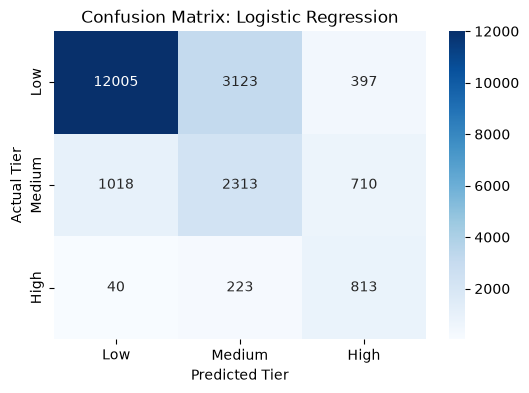

In [40]:
lr_results = evaluate_model(best_lr, X_val_lr, y_val, model_name="Logistic Regression")

### 4.2. Random Forest Classifier

A `RandomForestClassifier` is trained on the unscaled feature matrix (`X_train_final`) to capture non-linear feature interactions. Hyperparameters—including tree count (`n_estimators`), maximum depth (`max_depth`), minimum leaf size (`min_samples_leaf`), feature subsampling (`max_features`), and class weighting (`balanced_subsample` vs. `None`)—are tuned via 5-fold `RandomizedSearchCV` (`n_iter=15`) optimizing for `F1-Macro`. The optimal estimator is serialized via `joblib` and evaluated on the validation set.

In [41]:
from sklearn.ensemble import RandomForestClassifier

rf_param_dist = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [20, 30, 50, None],
    "min_samples_leaf": [2, 5, 10, 20],
    "max_features": ["sqrt", 0.1, 0.2],
    "class_weight": ["balanced_subsample", None],
}

base_rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)

rf_cv = RandomizedSearchCV(
    estimator=base_rf,
    param_distributions=rf_param_dist,
    n_iter=15,
    cv=5,
    scoring="f1_macro",
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)

rf_cv.fit(X_train_final, y_train)

best_rf = rf_cv.best_estimator_
print(f"Best parameters: {rf_cv.best_params_}")

Best parameters: {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 0.1, 'max_depth': 50, 'class_weight': 'balanced_subsample'}


In [42]:
joblib.dump(best_rf, "best_random_forest.joblib")

['best_random_forest.joblib']

In [43]:
best_rf = joblib.load("best_random_forest.joblib")

=== Random Forest Classifier ===
Accuracy:        0.7945
F1-Score (Macro): 0.6610
ROC AUC (Macro):  0.8815

              precision    recall  f1-score   support

         Low       0.89      0.88      0.89     15525
      Medium       0.50      0.50      0.50      4041
        High       0.58      0.62      0.60      1076

    accuracy                           0.79     20642
   macro avg       0.66      0.67      0.66     20642
weighted avg       0.79      0.79      0.79     20642



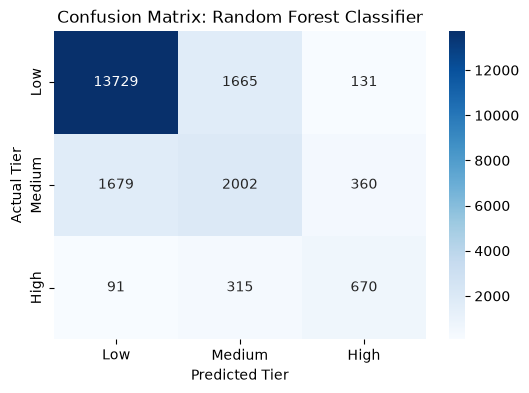

In [44]:
rf_results = evaluate_model(
    best_rf, X_val_final, y_val, model_name="Random Forest Classifier"
)

### 4.3. Gradient Boosting: XGBoost Classifier (Bayesian Optimization)

An `XGBClassifier` (`objective='multi:softprob'`, `tree_method='hist'`) is optimized via Bayesian hyperparameter search (**Optuna**, 15 trials, 3-fold CV). To mitigate class imbalance without inducing severe false-positive drift toward minority tiers, square-root-smoothed sample weights (`np.sqrt(compute_sample_weight('balanced', ...))`) are applied during fitting, while an unweighted `make_scorer(f1_score, average='macro')` ensures unbiased cross-validation scoring. Search spaces span tree complexity (`max_depth`, `min_child_weight`), learning dynamics (`n_estimators`, `learning_rate`), stochastic subsampling (`subsample`, `colsample_bytree`), and L1/L2 regularization (`reg_alpha`, `reg_lambda`). The optimal model is serialized natively in JSON format (`best_xgboost.json`) and evaluated on the validation subset.

In [ ]:
import optuna
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_val_score
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

sample_weights_sqrt = np.sqrt(compute_sample_weight("balanced", y_train))
honest_f1 = make_scorer(f1_score, average="macro")


def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 500),
        "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 4, 7),
        "min_child_weight": trial.suggest_int("min_child_weight", 5, 20),
        "subsample": trial.suggest_float("subsample", 0.7, 0.95),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 0.85),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "objective": "multi:softprob",
        "num_class": 3,
        "tree_method": "hist",
        "random_state": RANDOM_STATE,
        "n_jobs": N_JOBS,
    }

    model = XGBClassifier(**params)

    score = cross_val_score(
        model,
        X_train_final,
        y_train,
        cv=3,
        scoring=honest_f1,
        n_jobs=1,
        params={"sample_weight": sample_weights_sqrt},
    )

    return score.mean()


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15)

print(f"\nBest F1-Macro in CV: {study.best_value:.4f}")
print(f"Best parameters: {study.best_params}")

best_xgb = XGBClassifier(
    **study.best_params,
    objective="multi:softprob",
    num_class=3,
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)
best_xgb.fit(X_train_final, y_train, sample_weight=sample_weights_sqrt)

/home/sn/Projects/steam-success-predictor/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-12 11:16:10,680] A new study created in memory with name: no-name-b1491422-e4d0-406c-af9f-5e0d5f57792e
[I 2026-11-12 11:17:15,521] Trial 0 finished with value: 0.6735089695006894 and parameters: {'n_estimators': 286, 'learning_rate': 0.11178429283538531, 'max_depth': 4, 'min_child_weight': 14, 'subsample': 0.843157912389155, 'colsample_bytree': 0.639856379260215, 'reg_alpha': 6.931308874443421, 'reg_lambda': 0.0537105307125789}. Best is trial 0 with value: 0.6735089695006894.
[I 2026-11-12 11:20:02,576] Trial 1 finished with value: 0.6776863702934265 and parameters: {'n_estimators': 499, 'learning_rate': 0.06503300351016951, 'max_depth': 6, 'min_child_weight': 12, 'subsample': 0.8915749206136818, '


Best F1-Macro in CV: 0.6785
Best parameters: {'n_estimators': 224, 'learning_rate': 0.0651641427774416, 'max_depth': 7, 'min_child_weight': 14, 'subsample': 0.865423045790244, 'colsample_bytree': 0.5074318643962501, 'reg_alpha': 0.18684985740759733, 'reg_lambda': 0.4659707668127148}


,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.5074318643962501
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: pyth

=== XGBoost Classifier ===
Accuracy:        0.8078
F1-Score (Macro): 0.6809
ROC AUC (Macro):  0.8937

              precision    recall  f1-score   support

         Low       0.89      0.90      0.89     15525
      Medium       0.53      0.51      0.52      4041
        High       0.63      0.63      0.63      1076

    accuracy                           0.81     20642
   macro avg       0.68      0.68      0.68     20642
weighted avg       0.80      0.81      0.81     20642



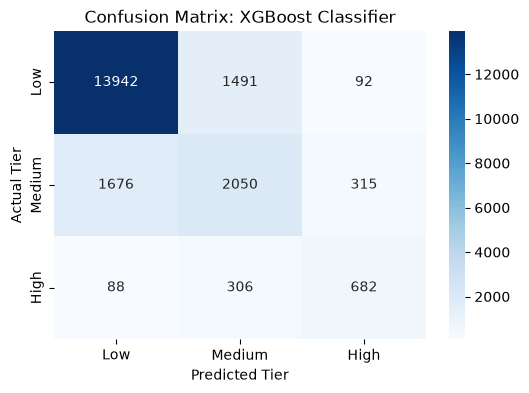

In [ ]:
best_xgb.save_model("best_xgboost.json")

In [48]:
best_xgb = XGBClassifier()
best_xgb.load_model("best_xgboost.json")

=== XGBoost Classifier ===
Accuracy:        0.8078
F1-Score (Macro): 0.6809
ROC AUC (Macro):  0.8937

              precision    recall  f1-score   support

         Low       0.89      0.90      0.89     15525
      Medium       0.53      0.51      0.52      4041
        High       0.63      0.63      0.63      1076

    accuracy                           0.81     20642
   macro avg       0.68      0.68      0.68     20642
weighted avg       0.80      0.81      0.81     20642



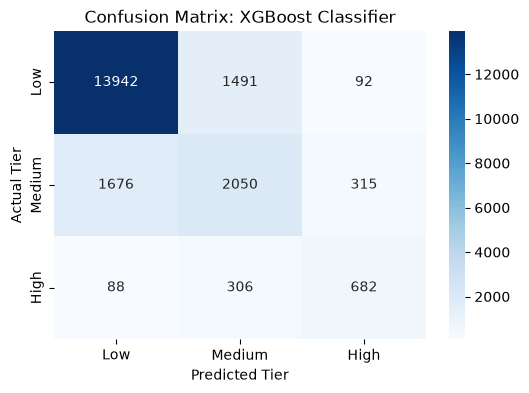

In [49]:
xgb_results = evaluate_model(
    best_xgb, X_val_final, y_val, model_name="XGBoost Classifier"
)

## 5. Model Comparison & Final Test Evaluation

### 5.1. Validation Performance Comparison
Validation metrics across all three tuned architectures are aggregated and ranked by `F1-Macro` to select the optimal candidate for final deployment.

In [50]:
comparison_df = pd.DataFrame([lr_results, rf_results, xgb_results])
comparison_df = comparison_df.set_index("Model").sort_values(
    by="F1_Macro", ascending=False
)

display(comparison_df)

,Accuracy,F1_Macro,ROC_AUC
Model,,,
XGBoost Classifier,0.807771,0.680877,0.893662
Random Forest Classifier,0.794545,0.661046,0.881533
Logistic Regression,0.733020,0.619831,0.862281


### 5.2. Final Hold-Out Test Evaluation
Based on superior validation performance across all target metrics (`F1-Macro: 0.6809`, `ROC AUC: 0.8937`), the tuned **XGBoost Classifier** is selected as the final model and evaluated once on the unseen test set (`X_test_final`) to establish unbiased generalization performance.

=== XGBoost (FINAL TEST) ===
Accuracy:        0.8071
F1-Score (Macro): 0.6746
ROC AUC (Macro):  0.8959

              precision    recall  f1-score   support

         Low       0.89      0.90      0.89     15525
      Medium       0.53      0.52      0.52      4041
        High       0.61      0.60      0.61      1076

    accuracy                           0.81     20642
   macro avg       0.68      0.67      0.67     20642
weighted avg       0.81      0.81      0.81     20642



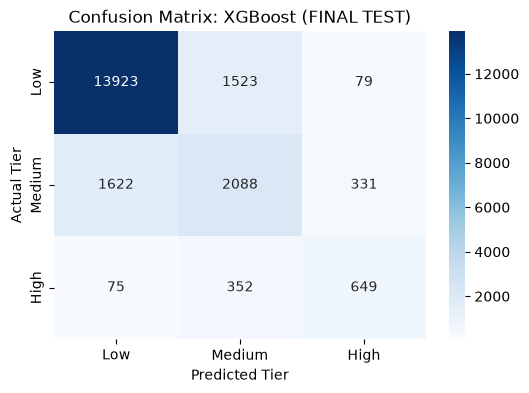

In [51]:
final_test_results = evaluate_model(
    best_xgb, X_test_final, y_test, model_name="XGBoost (FINAL TEST)"
)

## 6. Model Interpretability: Feature Importance Analysis

Gain-based feature importances extracted from the final **XGBoost** model reveal the top 15 primary drivers behind commercial tier predictions. Platform trust signals (`cat_Steam Trading Cards`), multiplayer/free-to-play mechanics, historical publisher performance (`TargetEncoder` probabilities), localization (`lang_French`), and engineered market competition metrics emerge as key predictors.

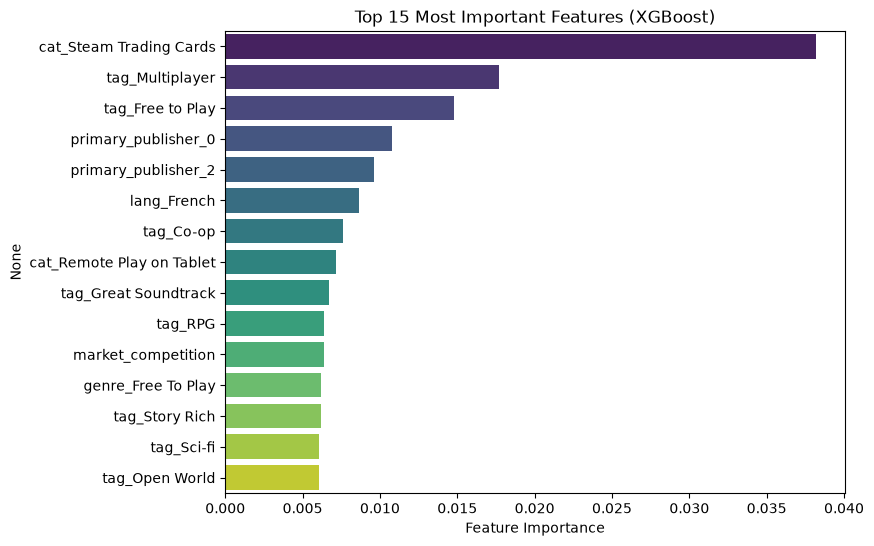

In [53]:
importances = pd.Series(best_xgb.feature_importances_, index=X_train_final.columns)
top_15_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(
    x=top_15_features.values,
    y=top_15_features.index,
    hue=top_15_features.index,
    palette="viridis",
)
plt.title("Top 15 Most Important Features (XGBoost)")
plt.xlabel("Feature Importance")
plt.show()